# Reinforcement learning from zero: learn the rules by playing

**QMB 6875 · Presentation 2 walkthrough**

Presentation 1 *solved* decision problems because it **knew the rules**: offers are Uniform(0,1), the gold premium is an AR(1) with $\mu=40,\rho=0.8,\sigma=20$.
Real decision makers are rarely told the rules. **Reinforcement learning (RL)** finds a good policy from experience alone:

> try something → get paid → update your estimates → repeat

Three problems, from simplest to hardest:

| # | Problem | States | What's learned | Check against |
|---|---------|--------|----------------|---------------|
| 1 | Which of 5 ads to show (a *bandit*) | 1 | which action pays best | the true click rates |
| 2 | Which offers to accept | 20 | $Q$(offer, accept/reject) | the exact answer 0.6262 |
| 3 | When the gold trader should ship | 38 | $Q$(premium, ship/hold) | optimal control's $50.49 |

**Colab:** run the next cell (edit the GitHub username in the clone line).

In [1]:
import os, sys
if not os.path.exists("../src") and not os.path.exists("qmb6875-2-reinforcement-learning"):
    # In Colab: uncomment the next line and put in the right GitHub username
    # !git clone https://github.com/YOUR-USERNAME/qmb6875-2-reinforcement-learning.git
    pass
for p in ["../src", "qmb6875-2-reinforcement-learning/src", "src"]:
    if os.path.exists(p):
        sys.path.insert(0, os.path.abspath(p))
import numpy as np
import matplotlib.pyplot as plt
from rlearn import bandit, offer_rl, gold_rl
print("ready")

ready


## 1. The bandit: explore vs. exploit, and nothing else

Five ad creatives with click rates the agent does **not** know: 2%, 3%, 3.5%, 4%, 5%. Each impression either gets a click (reward 1) or doesn't.

* **Greedy**: always show the best-looking ad. It can lock onto a bad ad after an unlucky start.
* **ε-greedy**: show a random ad with probability ε.
* **UCB1**: add an "uncertainty bonus" to rarely tried ads.
* **Thompson sampling**: draw a plausible click rate for each ad from its posterior and show the highest draw.
* **A/B test then commit**: the classic marketing experiment. Split traffic evenly for 2,000 impressions, then show the winner forever.

**Regret** = clicks lost compared with someone who knew the best ad from the start. 500 independent experiments of 10,000 impressions each:

strategy                 regret (clicks)   best ad shown, last 1,000
greedy                             117.9                       32.0%
epsilon-greedy (0.1)                54.2                       73.6%
epsilon-greedy (0.01)               89.0                       50.0%
UCB1                               129.4                       29.6%
Thompson sampling                   47.9                       84.6%
A/B test then commit                62.4                       66.9%


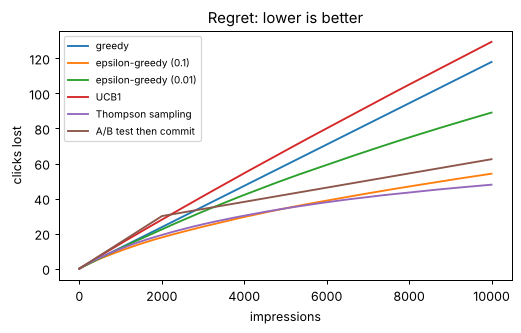

In [2]:
res = bandit.compare(horizon=10_000, runs=500)
print(f"{'strategy':<24}{'regret (clicks)':>16}{'best ad shown, last 1,000':>28}")
for name, r in res.items():
    print(f"{name:<24}{r['regret'][-1]:>16.1f}{r['best_share'][-1000:].mean():>28.1%}")

plt.figure(figsize=(6.5, 3.6))
for name, r in res.items():
    plt.plot(r["regret"], label=name)
plt.xlabel("impressions"); plt.ylabel("clicks lost"); plt.legend(fontsize=8); plt.title("Regret: lower is better")

**Reading it:**
- Greedy locks onto the wrong ad about two-thirds of the time.
- UCB1 *over*-explores here, because its bonus assumes rewards could be anywhere in [0, 1] while click rates are only 2–5%.
- Thompson sampling explores in proportion to its doubt and wins.
- A/B testing wastes 2,000 impressions showing known-bad ads, and then can never correct a wrong winner.

## 2. The offer problem, learned with Q-learning

The agent sees an offer (rounded to one of 20 levels) and accepts or rejects. It is never told offers are uniform.

$Q(s,a)$ is a **report card**: the value of action $a$ with offer $s$, then playing well. After every step it is nudged toward what just happened:

$$Q(s,a)\leftarrow Q(s,a)+\alpha\Big[\underbrace{r+\beta\max_{a'}Q(s',a')}_{\text{what just happened}}-\underbrace{Q(s,a)}_{\text{old guess}}\Big]$$

**The target:** the exact answer for 20 offer levels is $V^*=0.6262$ (the continuous answer from Presentation 1 is 0.6268).

In [3]:
V = offer_rl.true_value()
print(f"exact value of waiting (20 levels): {V:.4f}")

for label, kw in [("Q-learning, alpha=0.1, 20k episodes", dict(alpha=0.1, episodes=20_000)),
                  ("Q-learning, decaying alpha, 100k   ", dict(alpha="decay", episodes=100_000))]:
    s = offer_rl.summary("q", seeds=range(5), **kw)
    print(f"{label}: learned value {s['value_mean']:.4f} (sd across seeds {s['value_sd']:.4f}), cutoffs {s['cutoffs']}")

s = offer_rl.summary("sarsa", alpha="decay", episodes=100_000, seeds=range(5))
print(f"\nSARSA (on-policy) learns {s['value_mean']:.4f}; the exact value of a policy that explores 20% "
      f"of the time is {offer_rl.epsilon_greedy_value(0.2):.4f}")

exact value of waiting (20 levels): 0.6262
Q-learning, alpha=0.1, 20k episodes: learned value 0.6229 (sd across seeds 0.0120), cutoffs [0.625, 0.625, 0.625, 0.625, 0.625]
Q-learning, decaying alpha, 100k   : learned value 0.6260 (sd across seeds 0.0010), cutoffs [0.625, 0.675, 0.625, 0.625, 0.675]

SARSA (on-policy) learns 0.5768; the exact value of a policy that explores 20% of the time is 0.5762


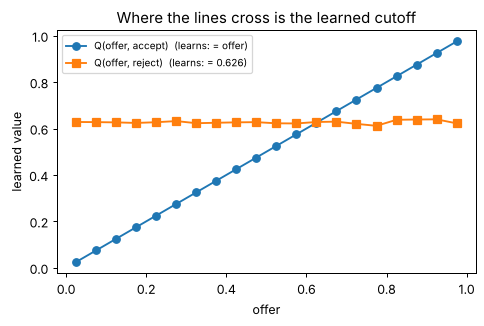

In [4]:
Q, _ = offer_rl.learn(alpha="decay", episodes=100_000)
w = offer_rl.offer_levels()
plt.figure(figsize=(6, 3.5))
plt.plot(w, Q[:, 0], "o-", label="Q(offer, accept)  (learns: = offer)")
plt.plot(w, Q[:, 1], "s-", label="Q(offer, reject)  (learns: = 0.626)")
plt.xlabel("offer"); plt.ylabel("learned value"); plt.legend(fontsize=8)
plt.title("Where the lines cross is the learned cutoff")

**Why 0.625 *or* 0.675?** The exact $V^*=0.6262$ sits a hair above the 0.625 level. Accepting 0.625 or rejecting it are almost equally good (values 0.62609 vs 0.62620), so learning noise decides. Either rule loses at most 0.0001.

**SARSA vs. Q-learning.** SARSA learns the value of the policy it is *actually following*, random exploration mistakes included (0.576). Q-learning learns the value of the *best* policy while exploring (0.626). That is "on-policy" vs. "off-policy".

## 3. The gold trader learns his own shipping rule

The professor's capstone story: a student used RL on his mother's trading records. Here the agent lives through simulated weeks of an AR(1) premium it is never told about. It sees the premium in $5 bins: ship (get $s-K$) or hold (pay $h$=$2.89 and wait).

In [5]:
dp = gold_rl.dp_cutoff()
print(f"optimal-control answer (knows the model): ship iff premium >= ${dp:.2f}")
for seed in range(3):
    Qg, visits, _ = gold_rl.learn(episodes=200_000, seed=seed)
    print(f"  agent {seed}: learned to ship from ${gold_rl.learned_cutoff(Qg):.0f}  "
          f"(after {visits.sum():,.0f} simulated weeks)")

v_opt, se = gold_rl.evaluate(dp)
print(f"\nvalue of the optimal rule:  ${v_opt:.2f}/oz (95% interval +/- {1.96*se:.2f})")
print(f"value of the learned rule:  ${gold_rl.evaluate(50.0)[0]:.2f}/oz")
print(f"value of shipping at once:  ${gold_rl.evaluate(-np.inf)[0]:.2f}/oz")

optimal-control answer (knows the model): ship iff premium >= $50.49
  agent 0: learned to ship from $50  (after 727,739 simulated weeks)
  agent 1: learned to ship from $50  (after 734,591 simulated weeks)
  agent 2: learned to ship from $50  (after 733,542 simulated weeks)

value of the optimal rule:  $26.59/oz (95% interval +/- 0.40)
value of the learned rule:  $26.64/oz
value of shipping at once:  $14.86/oz


**Takeaway.** Never told $\mu$, $\rho$, $\sigma$, the agent lands in the $5 bin that contains the true cutoff and earns the same $26.6/oz. The price: about **740,000 simulated weeks**, roughly 14,000 years of a real trader's life. That is why the capstone student needed his mother's whole file cabinet, and why you use the math when you know the model.

## Try it yourself
1. `offer_rl.learn(alpha=0.01, eps=0.05)`: why does it fail? (Hint: how often is "reject" tried at high offers?)
2. Set `bandit.CTRS = np.array([0.02, 0.10, 0.03, 0.04, 0.05])` and rerun. Which strategies benefit from a big gap?
3. In `gold_rl.learn`, try `eps=0.05` and `episodes=20_000`. How many agents still find $50?